# F1 race prediction pipeline

This notebook builds a historical Formula 1 dataset, trains and evaluates race-finishing-position models, and exports predictions for the latest completed race and the next scheduled race.

**Workflow**
1. Retrieve race results and championship standings from Jolpica-F1.
2. Prepare the historical dataset and create previous-race predictors.
3. Train and evaluate regression models using chronological, race-level validation.
4. Generate predictions for the latest completed race and the next scheduled race.
5. Export the results as JSON for the web application.

**Modelling notes**
- The target is the numeric classified finishing position (`positionOrder`).
- Each predictor uses information from the driver's previous race.
- The six predictors are `grid`, `positionOrder`, driver points per round, driver wins per round, constructor points per round, and constructor wins per round, all lagged by one race.
- Unclassified results are retained for the actual-results display but excluded from regression training.
- Drivers from the same race remain in the same train/test group.

In [1]:
# Import packages
import hashlib
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import fastf1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

from sklearn.base import clone
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Reduce FastF1 log messages
fastf1.set_log_level("ERROR")

# Configure API and local data directories
BASE_URL = "https://api.jolpi.ca/ergast/f1"
CACHE_DIR = Path("f1_api_cache")
SEASON_DIR = Path("f1_historical_data_v3")
SCHEDULE_DIR = Path("f1_schedule_cache")

for directory in [CACHE_DIR, SEASON_DIR, SCHEDULE_DIR]:
    directory.mkdir(exist_ok=True)

http = requests.Session()

## 1. Retrieve and cache Jolpica-F1 data

The helper below retrieves Jolpica-F1 API responses and stores successful responses locally. Cached responses are reused unless `refresh=True` is specified.

In [ ]:
def get_api_data(endpoint, params=None, refresh=False):
    """Retrieve one Jolpica endpoint, using a local cache when available."""

    url = f"{BASE_URL}/{endpoint}.json"

    # Create a stable cache filename from the endpoint and query parameters
    cache_key = json.dumps([endpoint, params], sort_keys=True)
    cache_name = hashlib.md5(cache_key.encode()).hexdigest()
    cache_file = CACHE_DIR / f"{cache_name}.json"

    if cache_file.exists() and not refresh:
        with open(cache_file, "r") as file:
            return json.load(file)

    # Retry rate limits, temporary server errors and connection failures
    for attempt in range(6):

        try:
            response = http.get(url, params=params, timeout=90)

            if response.status_code == 429:
                retry_after = response.headers.get("Retry-After")
                wait = int(retry_after) if retry_after else 2 ** attempt

                print(f"Rate limited. Retrying in {wait} seconds...")
                time.sleep(wait)
                continue

            response.raise_for_status()

            data = response.json()

            with open(cache_file, "w") as file:
                json.dump(data, file)

            return data

        except requests.exceptions.RequestException as error:

            if attempt == 5:
                raise

            wait = 2 ** attempt

            print(f"API request failed: {error}")
            print(f"Retrying in {wait} seconds...")

            time.sleep(wait)

    raise RuntimeError(f"Could not retrieve {endpoint} after 6 attempts.")

## 2. Retrieve race results and championship standings

Race results are paginated because the API limits the number of records returned per request. Results from separate pages are combined by race so that a race split across pages is reconstructed correctly.

Championship statistics are recorded after each race and later shifted to become predictors for the driver's next race.

In [3]:
def get_season_results(year, refresh=False):
    """Retrieve all race results for a season using API pagination."""

    limit = 100
    offset = 0
    races_by_round = {}

    while True:
        data = get_api_data(
            f"{year}/results",
            params={"limit": limit, "offset": offset},
            refresh=refresh
        )

        races = data["RaceTable"]["Races"]
        total = int(data["total"])

        # Combine results in case a race spans multiple API pages
        for race in races:
            round_number = int(race["round"])

            if round_number not in races_by_round:
                races_by_round[round_number] = {
                    key: value
                    for key, value in race.items()
                    if key != "Results"
                }
                races_by_round[round_number]["Results"] = []

            races_by_round[round_number]["Results"].extend(
                race.get("Results", [])
            )

        print(
            f"{year}: Retrieved {min(offset + limit, total)} "
            f"of {total} result records"
        )

        offset += limit
        if offset >= total or not races:
            break

    # Flatten the collected race results into rows
    season_results = []

    for round_number in sorted(races_by_round):
        race = races_by_round[round_number]

        for result in race["Results"]:
            season_results.append({
                "raceId": int(f"{year}{round_number}"),
                "year": int(year),
                "round": round_number,
                "date": race["date"],
                "driverId": result["Driver"]["driverId"],
                "constructorId": result["Constructor"]["constructorId"],
                "grid": result.get("grid"),
                "positionOrder": result.get("position")
            })

    return pd.DataFrame(season_results)


def get_race_standings(year, round_number, refresh=False):
    """Retrieve driver and constructor standings after a specified race."""

    driver_data = get_api_data(
        f"{year}/{round_number}/driverStandings",
        refresh=refresh
    )

    driver_standings = {}
    driver_lists = driver_data["StandingsTable"]["StandingsLists"]

    if driver_lists:
        for driver in driver_lists[0]["DriverStandings"]:
            driver_id = driver["Driver"]["driverId"]
            driver_standings[driver_id] = {
                "driver_points_per_round":
                    float(driver["points"]) / round_number,
                "driver_wins_per_round":
                    int(driver["wins"]) / round_number
            }

    constructor_data = get_api_data(
        f"{year}/{round_number}/constructorStandings",
        refresh=refresh
    )

    constructor_standings = {}
    constructor_lists = constructor_data["StandingsTable"]["StandingsLists"]

    if constructor_lists:
        for constructor in constructor_lists[0]["ConstructorStandings"]:
            constructor_id = constructor["Constructor"]["constructorId"]
            constructor_standings[constructor_id] = {
                "constructor_points_per_round":
                    float(constructor["points"]) / round_number,
                "constructor_wins_per_round":
                    int(constructor["wins"]) / round_number
            }

    return driver_standings, constructor_standings

In [4]:
def build_historical_dataset(start_year, end_year):
    """Build a combined dataset of race results and post-race standings."""

    all_seasons = []
    current_year = pd.Timestamp.now().year

    for year in range(start_year, end_year + 1):
        season_file = SEASON_DIR / f"{year}.csv"

        # Refresh the current season; reuse saved data for completed seasons
        refresh = year == current_year

        if season_file.exists() and not refresh:
            print(f"Loading {year} from saved CSV...")
            all_seasons.append(pd.read_csv(season_file))
            continue

        print(f"Processing {year}...")
        season_results = get_season_results(year, refresh=refresh)

        if season_results.empty:
            print(f"No results found for {year}.")
            continue

        standings_columns = [
            "driver_points_per_round",
            "driver_wins_per_round",
            "constructor_points_per_round",
            "constructor_wins_per_round"
        ]

        season_results[standings_columns] = np.nan

        # Attach standings recorded after each completed race
        for round_number in sorted(season_results["round"].unique()):
            driver_standings, constructor_standings = get_race_standings(
                year,
                int(round_number),
                refresh=refresh
            )

            race_mask = season_results["round"] == round_number

            for column in [
                "driver_points_per_round",
                "driver_wins_per_round"
            ]:
                season_results.loc[race_mask, column] = (
                    season_results.loc[race_mask, "driverId"].map({
                        key: value[column]
                        for key, value in driver_standings.items()
                    })
                )

            for column in [
                "constructor_points_per_round",
                "constructor_wins_per_round"
            ]:
                season_results.loc[race_mask, column] = (
                    season_results.loc[race_mask, "constructorId"].map({
                        key: value[column]
                        for key, value in constructor_standings.items()
                    })
                )

        season_results.to_csv(season_file, index=False)
        all_seasons.append(season_results)
        print(f"Saved {year}.")

    if not all_seasons:
        raise ValueError("No historical race data was retrieved.")

    return pd.concat(all_seasons, ignore_index=True)

## 3. Build the historical dataset

Retrieve the selected seasons and save a combined CSV for reference. Existing season CSVs are reused, while the current season is refreshed.

In [5]:
# Retrieve historical race results and standings
start_year = 2010
end_year = pd.Timestamp.now().year

combined_results = build_historical_dataset(start_year, end_year)

# Save a combined copy of the historical data
combined_results.to_csv("historical_f1_results.csv", index=False)

print("Dataset shape:", combined_results.shape)
display(combined_results.head())

Loading 2010 from saved CSV...
Loading 2011 from saved CSV...
Loading 2012 from saved CSV...
Loading 2013 from saved CSV...
Loading 2014 from saved CSV...
Loading 2015 from saved CSV...
Loading 2016 from saved CSV...
Loading 2017 from saved CSV...
Loading 2018 from saved CSV...
Loading 2019 from saved CSV...
Loading 2020 from saved CSV...
Loading 2021 from saved CSV...
Loading 2022 from saved CSV...
Loading 2023 from saved CSV...
Loading 2024 from saved CSV...
Loading 2025 from saved CSV...
Processing 2026...
2026: Retrieved 100 of 462 result records
2026: Retrieved 200 of 462 result records
2026: Retrieved 300 of 462 result records
2026: Retrieved 400 of 462 result records
2026: Retrieved 462 of 462 result records
Saved 2026.
Dataset shape: (7373, 12)


,raceId,year,round,date,driverId,constructorId,grid,positionOrder,driver_points_per_round,driver_wins_per_round,constructor_points_per_round,constructor_wins_per_round
0,20101,2010,1,2010-03-14,alonso,ferrari,3,1,25.0,1.0,43.0,1.0
1,20101,2010,1,2010-03-14,massa,ferrari,2,2,18.0,0.0,43.0,1.0
2,20101,2010,1,2010-03-14,hamilton,mclaren,4,3,15.0,0.0,21.0,0.0
3,20101,2010,1,2010-03-14,vettel,red_bull,1,4,12.0,0.0,16.0,0.0
4,20101,2010,1,2010-03-14,rosberg,mercedes,5,5,10.0,0.0,18.0,0.0


## 4. Clean the data and create lagged predictors

Keep a copy of the raw results for the website's actual-results display. The modelling dataset excludes rows without a numeric classified finishing position, then creates each driver's previous-race predictors.

All six predictors are used consistently in model training and future-race prediction.

In [6]:
# Preserve all results for the actual-results output
all_results = combined_results.copy()

# Convert modelling columns to numeric values
numeric_columns = [
    "grid",
    "positionOrder",
    "driver_points_per_round",
    "driver_wins_per_round",
    "constructor_points_per_round",
    "constructor_wins_per_round"
]

combined_results[numeric_columns] = (
    combined_results[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Convert dates and retain rows with a usable target
combined_results["date"] = pd.to_datetime(
    combined_results["date"],
    errors="coerce"
)

all_results["date"] = pd.to_datetime(
    all_results["date"],
    errors="coerce"
)

all_results["positionOrder"] = pd.to_numeric(
    all_results["positionOrder"],
    errors="coerce"
)

combined_results = combined_results.dropna(
    subset=["date", "positionOrder"]
).copy()

# Sort each driver's races chronologically
combined_results = combined_results.sort_values(
    ["driverId", "date", "year", "round"]
).reset_index(drop=True)

# Define the six variables to lag by one race
lag_columns = [
    "grid",
    "positionOrder",
    "driver_points_per_round",
    "driver_wins_per_round",
    "constructor_points_per_round",
    "constructor_wins_per_round"
]

# Create previous-race values for each driver
for column in lag_columns:
    combined_results[f"{column}_lag1"] = (
        combined_results.groupby("driverId")[column].shift(1)
    )

features = [
    "grid_lag1",
    "positionOrder_lag1",
    "driver_points_per_round_lag1",
    "driver_wins_per_round_lag1",
    "constructor_points_per_round_lag1",
    "constructor_wins_per_round_lag1"
]

# Remove rows without a complete set of lagged predictors
lagged_results = combined_results.dropna(
    subset=features
).copy().reset_index(drop=True)

# Ensure race IDs are numeric
lagged_results["raceId"] = pd.to_numeric(
    lagged_results["raceId"],
    errors="coerce"
)

# Create the modelling predictors and target
X = lagged_results[features].astype(float)
y = lagged_results["positionOrder"].astype(float)

# Remove any rows with non-finite predictor values
finite_rows = np.isfinite(X).all(axis=1) & np.isfinite(y)
lagged_results = lagged_results.loc[finite_rows].copy().reset_index(drop=True)
X = lagged_results[features].astype(float)
y = lagged_results["positionOrder"].astype(float)

print("Rows available for modelling:", len(lagged_results))
print("\nMissing predictor values:")
print(X.isna().sum())

display(
    lagged_results[
        [
            "year", "round", "driverId",
            "grid", "grid_lag1",
            "positionOrder", "positionOrder_lag1",
            "driver_points_per_round_lag1",
            "constructor_points_per_round_lag1"
        ]
    ].head(10)
)

Rows available for modelling: 7287

Missing predictor values:
grid_lag1                            0
positionOrder_lag1                   0
driver_points_per_round_lag1         0
driver_wins_per_round_lag1           0
constructor_points_per_round_lag1    0
constructor_wins_per_round_lag1      0
dtype: int64


,year,round,driverId,grid,grid_lag1,positionOrder,positionOrder_lag1,driver_points_per_round_lag1,constructor_points_per_round_lag1
0,2019,2,albon,12,13.0,9,14.0,0.000000,1.000000
1,2019,3,albon,0,12.0,10,9.0,1.000000,1.500000
2,2019,4,albon,11,0.0,11,10.0,1.000000,1.333333
3,2019,5,albon,11,11.0,11,11.0,0.750000,1.000000
4,2019,6,albon,10,11.0,8,11.0,0.600000,1.200000
5,2019,7,albon,13,10.0,19,8.0,1.166667,2.666667
6,2019,8,albon,11,13.0,15,19.0,1.000000,2.428571
7,2019,9,albon,18,11.0,15,15.0,0.875000,2.125000
8,2019,10,albon,9,18.0,12,15.0,0.777778,1.888889
9,2019,11,albon,16,9.0,6,12.0,0.700000,1.900000


## 5. Create chronological, race-level training and test sets

The latest 10% of races are reserved for testing. All drivers from a race remain together, and the test set contains later races than the training set.

In [7]:
# Get unique races in chronological order
race_calendar = (
    lagged_results[["raceId", "date", "year", "round"]]
    .drop_duplicates(subset="raceId")
    .sort_values(["date", "year", "round"])
    .reset_index(drop=True)
)

if len(race_calendar) < 10:
    raise ValueError("Not enough races to create the chronological test split.")

# Reserve the latest 10% of races for the final test set
test_race_count = max(1, int(np.ceil(len(race_calendar) * 0.10)))
test_race_ids = race_calendar.tail(test_race_count)["raceId"]

train_data = (
    lagged_results[~lagged_results["raceId"].isin(test_race_ids)]
    .sort_values(["date", "year", "round", "driverId"])
    .reset_index(drop=True)
)

test_data = (
    lagged_results[lagged_results["raceId"].isin(test_race_ids)]
    .sort_values(["date", "year", "round", "driverId"])
    .reset_index(drop=True)
)

X_train = train_data[features].astype(float)
X_test = test_data[features].astype(float)
y_train = train_data["positionOrder"].astype(float)
y_test = test_data["positionOrder"].astype(float)

print("Training races:", train_data["raceId"].nunique())
print("Testing races:", test_data["raceId"].nunique())
print("Training rows:", len(train_data))
print("Testing rows:", len(test_data))
print("\nTraining date range:", train_data["date"].min(), "to", train_data["date"].max())
print("Testing date range:", test_data["date"].min(), "to", test_data["date"].max())

Training races: 314
Testing races: 35
Training rows: 6548
Testing rows: 739

Training date range: 2010-03-28 00:00:00 to 2025-06-15 00:00:00
Testing date range: 2025-06-29 00:00:00 to 2026-11-22 00:00:00


## 6. Create chronological cross-validation folds

Each fold trains on earlier races and validates on later races. Race groups are kept intact throughout cross-validation.

In [8]:
# Build cross-validation splits using race IDs
train_races = (
    train_data[["raceId", "date", "year", "round"]]
    .drop_duplicates(subset="raceId")
    .sort_values(["date", "year", "round"])
    .reset_index(drop=True)
)

if len(train_races) < 6:
    raise ValueError("Not enough training races for five chronological CV folds.")

time_splitter = TimeSeriesSplit(n_splits=5)
cv_splits = []

for earlier_race_idx, later_race_idx in time_splitter.split(train_races):
    earlier_race_ids = train_races.iloc[earlier_race_idx]["raceId"]
    later_race_ids = train_races.iloc[later_race_idx]["raceId"]

    # Convert race groups to row positions within train_data
    fold_train_idx = np.flatnonzero(
        train_data["raceId"].isin(earlier_race_ids).to_numpy()
    )
    fold_valid_idx = np.flatnonzero(
        train_data["raceId"].isin(later_race_ids).to_numpy()
    )

    cv_splits.append((fold_train_idx, fold_valid_idx))

print("Number of CV folds:", len(cv_splits))

Number of CV folds: 5


## 7. Explore predictor relationships

Inspect correlations and variance inflation factors using the training data only. Non-finite rows are excluded from the VIF calculation.

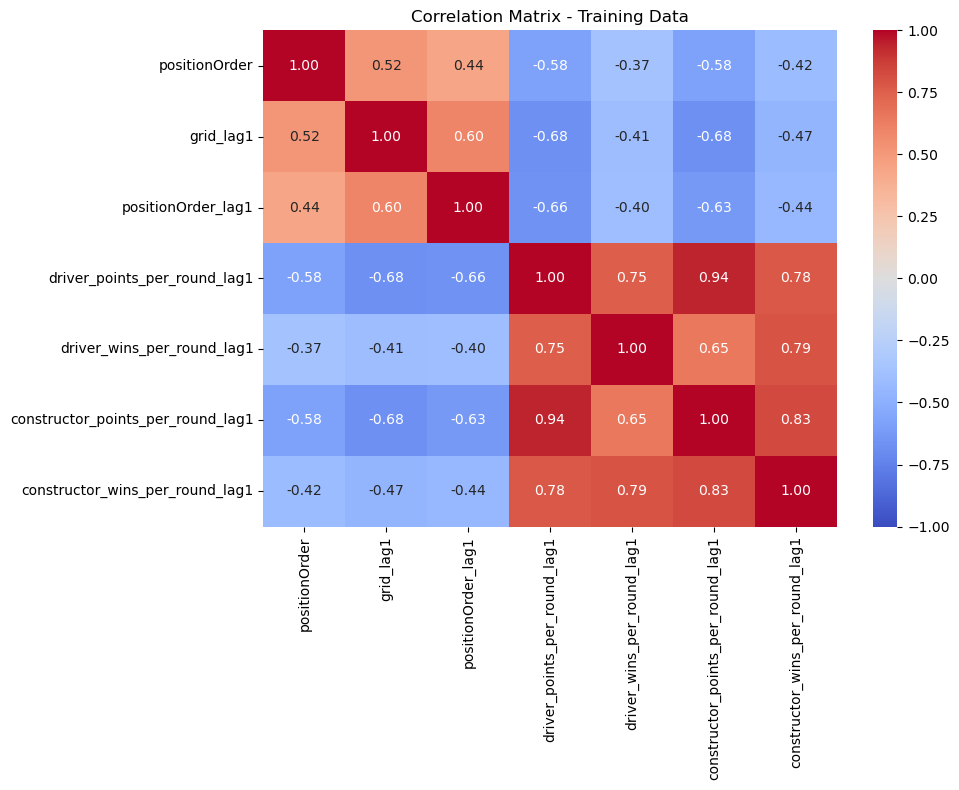

constructor_points_per_round_lag1   -0.580113
driver_points_per_round_lag1        -0.578747
grid_lag1                            0.522870
positionOrder_lag1                   0.444876
constructor_wins_per_round_lag1     -0.418049
driver_wins_per_round_lag1          -0.369975
Name: positionOrder, dtype: float64

,Variable,VIF
4,constructor_points_per_round_lag1,28.514616
2,driver_points_per_round_lag1,25.667622
5,constructor_wins_per_round_lag1,6.951078
1,positionOrder_lag1,5.645686
0,grid_lag1,5.475623
3,driver_wins_per_round_lag1,5.122056


In [9]:
# Calculate correlations using training data only
data_train = pd.concat(
    [y_train.rename("positionOrder"), X_train],
    axis=1
)

correlation_matrix = data_train.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation Matrix - Training Data")
plt.tight_layout()
plt.show()

# Display correlations with the target, ordered by absolute magnitude
target_correlations = correlation_matrix["positionOrder"].drop("positionOrder")
target_correlations = target_correlations.reindex(
    target_correlations.abs().sort_values(ascending=False).index
)
display(target_correlations)

# Calculate VIF using complete, finite predictor rows
X_vif = X_train.replace([np.inf, -np.inf], np.nan).dropna()

if len(X_vif) <= X_vif.shape[1]:
    print("Not enough complete observations to calculate VIF.")
else:
    vif = pd.DataFrame({
        "Variable": X_vif.columns,
        "VIF": [
            variance_inflation_factor(X_vif.to_numpy(), i)
            for i in range(X_vif.shape[1])
        ]
    })
    display(vif.sort_values("VIF", ascending=False))

## 8. Ridge regression

Ridge regression provides a regularised linear baseline. Predictors are standardised before fitting.

In [10]:
ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_mae_scores = []

for train_idx, valid_idx in cv_splits:
    ridge_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = ridge_model.predict(X_train.iloc[valid_idx])
    ridge_mae_scores.append(
        mean_absolute_error(y_train.iloc[valid_idx], predictions)
    )

print("Ridge CV MAE scores:", ridge_mae_scores)
print("Mean CV MAE:", np.mean(ridge_mae_scores))
print("SD of CV MAE:", np.std(ridge_mae_scores, ddof=1))

Ridge CV MAE scores: [3.8382902636058596, 3.760723299812936, 3.7869388456293196, 3.7380332809080996, 3.3830048943577102]
Mean CV MAE: 3.701398116862785
SD of CV MAE: 0.1818602023751344


## 9. Partial least squares regression

Partial least squares regression provides a second linear model that constructs components from the predictor variables.

In [11]:
pls_model = make_pipeline(
    StandardScaler(),
    PLSRegression(n_components=3)
)

pls_mae_scores = []

for train_idx, valid_idx in cv_splits:
    pls_model.fit(
        X_train.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    predictions = pls_model.predict(X_train.iloc[valid_idx]).ravel()
    pls_mae_scores.append(
        mean_absolute_error(y_train.iloc[valid_idx], predictions)
    )

print("PLS CV MAE scores:", pls_mae_scores)
print("Mean CV MAE:", np.mean(pls_mae_scores))
print("SD of CV MAE:", np.std(pls_mae_scores, ddof=1))

PLS CV MAE scores: [3.8374097865361794, 3.7720035044328872, 3.809485891286521, 3.7832821209084675, 3.4046604813543726]
Mean CV MAE: 3.7213683569036853
SD of CV MAE: 0.17883751286458763


## 10. Gradient Boosting regression

Grid search selects the Gradient Boosting hyperparameters using the chronological cross-validation folds and mean absolute error.

In [12]:
gb_param_grid = {
    "n_estimators": [150, 250],
    "learning_rate": [0.03, 0.05],
    "max_depth": [2, 3],
    "min_samples_split": [4],
    "min_samples_leaf": [3, 5]
}

gb_model = GradientBoostingRegressor(
    loss="squared_error",
    random_state=42
)

grid_search_gb = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

grid_search_gb.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(grid_search_gb.best_params_)

best_model_gb = grid_search_gb.best_estimator_

gb_cv_results = pd.DataFrame(grid_search_gb.cv_results_)
gb_cv_results["Mean CV MAE"] = -gb_cv_results["mean_test_score"]
gb_cv_results["SD of CV MAE"] = gb_cv_results["std_test_score"]
gb_cv_results = gb_cv_results.sort_values("Mean CV MAE")

display(gb_cv_results[[
    "param_n_estimators",
    "param_learning_rate",
    "param_max_depth",
    "param_min_samples_split",
    "param_min_samples_leaf",
    "Mean CV MAE",
    "SD of CV MAE"
]].head(10))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Gradient Boosting parameters:
{'learning_rate': 0.03, 'max_depth': 2, 'min_samples_leaf': 5, 'min_samples_split': 4, 'n_estimators': 250}


,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_split,param_min_samples_leaf,Mean CV MAE,SD of CV MAE
3,250,0.03,2,4,5,3.719551,0.134729
10,150,0.05,2,4,5,3.722435,0.135504
1,250,0.03,2,4,3,3.723417,0.138309
8,150,0.05,2,4,3,3.727404,0.140694
2,150,0.03,2,4,5,3.728019,0.136723
11,250,0.05,2,4,5,3.729042,0.122962
0,150,0.03,2,4,3,3.729657,0.137873
6,150,0.03,3,4,5,3.732099,0.127917
4,150,0.03,3,4,3,3.733483,0.130949
9,250,0.05,2,4,3,3.737591,0.131882


## 11. Neural network regression

The neural network uses standardised predictors. Grid search selects the network architecture and regularisation strength using the same chronological folds.

In [13]:
nn_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42,
        early_stopping=False
    )
)

nn_param_grid = {
    "mlpregressor__hidden_layer_sizes": [
        (64,),
        (64, 32),
        (128, 64)
    ],
    "mlpregressor__activation": ["relu", "tanh"],
    "mlpregressor__alpha": [0.001, 0.01],
    "mlpregressor__learning_rate_init": [0.001]
}

grid_search_nn = GridSearchCV(
    estimator=nn_model,
    param_grid=nn_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

grid_search_nn.fit(X_train, y_train)

print("Best neural network parameters:")
print(grid_search_nn.best_params_)

best_model_nn = grid_search_nn.best_estimator_

nn_cv_results = pd.DataFrame(grid_search_nn.cv_results_)
nn_cv_results["Mean CV MAE"] = -nn_cv_results["mean_test_score"]
nn_cv_results["SD of CV MAE"] = nn_cv_results["std_test_score"]
nn_cv_results = nn_cv_results.sort_values("Mean CV MAE")

display(nn_cv_results[[
    "param_mlpregressor__hidden_layer_sizes",
    "param_mlpregressor__activation",
    "param_mlpregressor__alpha",
    "param_mlpregressor__learning_rate_init",
    "Mean CV MAE",
    "SD of CV MAE"
]].head(10))

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best neural network parameters:
{'mlpregressor__activation': 'relu', 'mlpregressor__alpha': 0.001, 'mlpregressor__hidden_layer_sizes': (64,), 'mlpregressor__learning_rate_init': 0.001}


,param_mlpregressor__hidden_layer_sizes,param_mlpregressor__activation,param_mlpregressor__alpha,param_mlpregressor__learning_rate_init,Mean CV MAE,SD of CV MAE
0,"(64,)",relu,0.001,0.001,3.695428,0.137388
3,"(64,)",relu,0.010,0.001,3.704730,0.146263
9,"(64,)",tanh,0.010,0.001,3.707125,0.145470
6,"(64,)",tanh,0.001,0.001,3.707213,0.145478
10,"(64, 32)",tanh,0.010,0.001,3.713318,0.136334
7,"(64, 32)",tanh,0.001,0.001,3.714125,0.135739
4,"(64, 32)",relu,0.010,0.001,3.731116,0.202092
1,"(64, 32)",relu,0.001,0.001,3.732590,0.201677
2,"(128, 64)",relu,0.001,0.001,3.741091,0.151088
5,"(128, 64)",relu,0.010,0.001,3.754320,0.176512


## 12. Evaluate predictions by race

The selected neural network predicts numerical finishing positions for the held-out races. Predictions are then ranked within each race and compared with the actual classified positions.

In [14]:
# Use the selected neural network for the final test set
final_model = best_model_nn

y_pred = np.asarray(final_model.predict(X_test)).ravel()

test_results = test_data.copy()
test_results["predicted_position"] = y_pred

# Rank predicted positions within each race
test_results["predicted_rank"] = (
    test_results.groupby("raceId")["predicted_position"]
    .rank(method="first", ascending=True)
    .astype(int)
)

test_results = test_results.sort_values(
    ["year", "round", "predicted_rank"]
).reset_index(drop=True)

display(test_results[[
    "raceId",
    "year",
    "round",
    "driverId",
    "positionOrder",
    "predicted_position",
    "predicted_rank"
]].tail(30))

# Compare actual positions with predicted within-race ranks
absolute_errors = np.abs(
    test_results["positionOrder"] - test_results["predicted_rank"]
)

print("Ranked Prediction Performance")
print(f"MAE: {mean_absolute_error(test_results['positionOrder'], test_results['predicted_rank']):.4f}")
print(f"SD:  {absolute_errors.std(ddof=1):.4f}")

print("\nRaw Position Prediction Performance")
print(f"MAE: {mean_absolute_error(test_results['positionOrder'], test_results['predicted_position']):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(test_results['positionOrder'], test_results['predicted_position'])):.4f}")
print(f"R²: {r2_score(test_results['positionOrder'], test_results['predicted_position']):.4f}")

,raceId,year,round,driverId,positionOrder,predicted_position,predicted_rank
709,202620,2026,20,hulkenberg,10,13.252586,14
710,202620,2026,20,bearman,17,13.820680,15
711,202620,2026,20,albon,15,13.852414,16
712,202620,2026,20,sainz,19,13.888790,17
713,202620,2026,20,alonso,12,16.103792,18
714,202620,2026,20,perez,18,16.633277,19
715,202620,2026,20,stroll,21,16.823821,20
716,202620,2026,20,bottas,22,17.552470,21
717,202621,2026,21,antonelli,4,2.807267,1
718,202621,2026,21,russell,9,5.940391,2


Ranked Prediction Performance
MAE: 3.9756
SD:  3.6824

Raw Position Prediction Performance
MAE: 3.7284
RMSE: 4.7906
R²: 0.3941


## 13. Identify the latest completed race

Use the latest race in the retrieved results. Keep the full result list for the website, including drivers without a numeric classified finishing position.

In [15]:
# Identify the latest completed race
race_calendar_all = (
    all_results[["raceId", "date", "year", "round"]]
    .dropna(subset=["raceId", "date"])
    .drop_duplicates(subset="raceId")
    .sort_values(["date", "year", "round"])
    .reset_index(drop=True)
)

if race_calendar_all.empty:
    raise ValueError("No completed races are available.")

latest_race = race_calendar_all.iloc[-1]

latest_race_id = int(latest_race["raceId"])
latest_year = int(latest_race["year"])
latest_round = int(latest_race["round"])
latest_race_date = pd.to_datetime(latest_race["date"])

actual_results = all_results[
    all_results["raceId"] == latest_race_id
].copy()

actual_results = actual_results.sort_values(
    "positionOrder",
    na_position="last"
).reset_index(drop=True)

print(f"Latest completed race: {latest_year}, round {latest_round}")
print("Race date:", latest_race_date.date())

display(actual_results[[
    "driverId",
    "constructorId",
    "grid",
    "positionOrder"
]])

Latest completed race: 2026, round 21
Race date: 2026-11-22


,driverId,constructorId,grid,positionOrder
0,max_verstappen,red_bull,1,1
1,norris,mclaren,3,2
2,piastri,mclaren,17,3
3,antonelli,mercedes,6,4
4,gasly,alpine,8,5
5,colapinto,alpine,9,6
6,hamilton,ferrari,11,7
7,sainz,williams,20,8
8,russell,mercedes,2,9
9,leclerc,ferrari,10,10


## 14. Generate predictions for the latest completed race

The selected neural network is refitted using only races before the latest race. Its predictions for the latest race are therefore out-of-sample.

In [16]:
# Train using races before the latest completed race
training_data = lagged_results[
    lagged_results["date"] < latest_race_date
].copy()

latest_race_data = lagged_results[
    lagged_results["raceId"] == latest_race_id
].copy()

if training_data.empty:
    raise ValueError("No earlier races are available to train the latest-race model.")

if latest_race_data.empty:
    raise ValueError("No lagged predictor data found for the latest race.")

# Refit a fresh copy of the selected model
recent_model = clone(best_model_nn)
recent_model.fit(
    training_data[features],
    training_data["positionOrder"]
)

# Predict and rank finishing positions
latest_race_data["predicted_position"] = (
    recent_model.predict(latest_race_data[features]).ravel()
)

latest_race_data["predicted_rank"] = (
    latest_race_data["predicted_position"]
    .rank(method="first", ascending=True)
    .astype(int)
)

recent_predictions = latest_race_data.sort_values(
    "predicted_rank"
).reset_index(drop=True)

print("Predicted finishing order for the latest completed race:")
display(recent_predictions[[
    "predicted_rank",
    "driverId",
    "constructorId",
    "predicted_position"
]])

Predicted finishing order for the latest completed race:


,predicted_rank,driverId,constructorId,predicted_position
0,1,antonelli,mercedes,3.198852
1,2,russell,mercedes,5.972529
2,3,hamilton,ferrari,6.183103
3,4,max_verstappen,red_bull,6.309272
4,5,norris,mclaren,6.324843
5,6,leclerc,ferrari,6.834758
6,7,hadjar,red_bull,7.894283
7,8,piastri,mclaren,8.382937
8,9,lawson,rb,9.632229
9,10,arvid_lindblad,rb,12.385882


## 15. Identify the next scheduled race

Retrieve the current season calendar from FastF1 and select the next race. If the season has finished, check the following season. A local CSV copy is also maintained so the notebook can fall back to a previously retrieved calendar if the network is unavailable.

In [17]:
def get_season_schedule(year):
    """Retrieve a season schedule, using a local copy if the request fails."""

    schedule_file = SCHEDULE_DIR / f"schedule_{year}.csv"

    try:
        schedule = fastf1.get_event_schedule(year)
        schedule.to_csv(schedule_file, index=False)

    except Exception as error:
        if not schedule_file.exists():
            raise RuntimeError(
                f"Could not retrieve the {year} calendar and no local "
                f"cached schedule is available. Original error: {error}"
            ) from error

        print(
            f"Could not refresh the {year} calendar. "
            "Using the locally cached schedule."
        )
        schedule = pd.read_csv(schedule_file)

    schedule = schedule[schedule["RoundNumber"] > 0].copy()
    schedule["EventDate"] = pd.to_datetime(
        schedule["EventDate"],
        utc=True,
        errors="coerce"
    )

    return schedule


# Find the next scheduled race
now = pd.Timestamp.now(tz="UTC")
current_year = now.year

schedule = get_season_schedule(current_year)
upcoming_races = schedule[schedule["EventDate"] >= now].copy()

# Check the following season if the current season has finished
if upcoming_races.empty:
    next_calendar_year = current_year + 1
    schedule = get_season_schedule(next_calendar_year)
    upcoming_races = schedule[schedule["EventDate"] >= now].copy()

if upcoming_races.empty:
    raise ValueError("No upcoming race found in the available calendars.")

next_race = upcoming_races.sort_values("EventDate").iloc[0]
next_year = int(next_race["EventDate"].year)
next_round = int(next_race["RoundNumber"])

print(f"Next race: {next_race['EventName']}")
print(f"Year: {next_year}")
print(f"Round: {next_round}")
print(f"Date: {next_race['EventDate']}")

Next race: Qatar Grand Prix
Year: 2026
Round: 22
Date: 2026-11-29 00:00:00+00:00


## 16. Generate predictions for the next scheduled race

Construct the next race's predictors from the latest completed race and the championship standings recorded after it. The model is refitted on all available historical training data before generating the forecast.

**Assumption:** The next race is assumed to have the same driver and constructor lineup as the latest completed race. Update the lineup separately if there are driver replacements or team changes.

In [18]:
# Retrieve standings after the latest completed race
driver_standings, constructor_standings = get_race_standings(
    latest_year,
    latest_round,
    refresh=True
)

# Build the next race predictor rows
next_race_features = []

for _, row in actual_results.iterrows():
    driver_id = row["driverId"]
    constructor_id = row["constructorId"]

    driver_stats = driver_standings.get(driver_id)
    constructor_stats = constructor_standings.get(constructor_id)

    # Skip entries without standings or a usable previous-race result
    if driver_stats is None or constructor_stats is None:
        continue

    next_race_features.append({
        "raceId": int(f"{next_year}{next_round}"),
        "year": next_year,
        "round": next_round,
        "driverId": driver_id,
        "constructorId": constructor_id,
        "grid_lag1": row["grid"],
        "positionOrder_lag1": row["positionOrder"],
        "driver_points_per_round_lag1":
            driver_stats["driver_points_per_round"],
        "driver_wins_per_round_lag1":
            driver_stats["driver_wins_per_round"],
        "constructor_points_per_round_lag1":
            constructor_stats["constructor_points_per_round"],
        "constructor_wins_per_round_lag1":
            constructor_stats["constructor_wins_per_round"]
    })

next_race_data = pd.DataFrame(next_race_features)

if next_race_data.empty:
    raise ValueError("No drivers have sufficient data for next-race predictions.")

# Keep rows with complete, finite predictor values
next_race_data[features] = next_race_data[features].apply(
    pd.to_numeric,
    errors="coerce"
)
next_race_data = next_race_data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(subset=features).reset_index(drop=True)

if next_race_data.empty:
    raise ValueError("No complete predictor rows are available for the next race.")

# Refit the selected model using all available historical data
next_model = clone(best_model_nn)
next_model.fit(X, y)

# Predict and rank finishing positions
next_race_data["predicted_position"] = (
    next_model.predict(next_race_data[features]).ravel()
)

next_race_data["predicted_rank"] = (
    next_race_data["predicted_position"]
    .rank(method="first", ascending=True)
    .astype(int)
)

next_predictions = next_race_data.sort_values(
    "predicted_rank"
).reset_index(drop=True)

print(f"Predicted finishing order for {next_race['EventName']}:")
display(next_predictions[[
    "predicted_rank",
    "driverId",
    "constructorId",
    "predicted_position"
]])

Predicted finishing order for Qatar Grand Prix:


,predicted_rank,driverId,constructorId,predicted_position
0,1,antonelli,mercedes,4.072843
1,2,russell,mercedes,5.693173
2,3,max_verstappen,red_bull,5.868778
3,4,norris,mclaren,6.142508
4,5,hamilton,ferrari,6.855487
5,6,leclerc,ferrari,7.031333
6,7,piastri,mclaren,7.804526
7,8,hadjar,red_bull,8.188443
8,9,lawson,rb,10.718429
9,10,arvid_lindblad,rb,11.202870


## 17. Export predictions for web application

Save the latest-race predictions, actual results, and next-race predictions in one JSON file. The file is written to the `public` directory so a website can retrieve it as a static asset.

In [19]:
def dataframe_to_records(dataframe):
    """Convert a DataFrame to JSON-compatible records."""

    return json.loads(
        dataframe.to_json(
            orient="records",
            date_format="iso"
        )
    )


# Use the event name when it is available in the loaded calendar
latest_race_name = f"{latest_year} Round {latest_round}"

if latest_year == int(schedule["EventDate"].dt.year.iloc[0]):
    matching_event = schedule[schedule["RoundNumber"] == latest_round]
    if not matching_event.empty:
        latest_race_name = matching_event.iloc[0]["EventName"]

# Assemble the website data
f1_data = {
    "last_updated": datetime.now(timezone.utc).isoformat(),
    "latest_race": {
        "race_name": str(latest_race_name),
        "year": latest_year,
        "round": latest_round,
        "date": latest_race_date.isoformat(),
        "predictions": dataframe_to_records(
            recent_predictions[[
                "driverId",
                "constructorId",
                "predicted_position",
                "predicted_rank"
            ]]
        ),
        "actual_results": dataframe_to_records(
            actual_results[[
                "driverId",
                "constructorId",
                "grid",
                "positionOrder"
            ]]
        )
    },
    "upcoming_race": {
        "race_name": str(next_race["EventName"]),
        "year": next_year,
        "round": next_round,
        "date": next_race["EventDate"].isoformat(),
        "predictions": dataframe_to_records(
            next_predictions[[
                "driverId",
                "constructorId",
                "predicted_position",
                "predicted_rank"
            ]]
        )
    }
}

# Write the JSON file to the website's public directory
output_directory = Path("public")
output_directory.mkdir(exist_ok=True)

output_file = output_directory / "f1_predictions.json"

with open(output_file, "w") as file:
    json.dump(f1_data, file, indent=4)

print(f"Predictions saved to: {output_file}")

Predictions saved to: public/f1_predictions.json


In [20]:
# Reload the exported file and verify its contents
with open(output_file, "r") as file:
    saved_data = json.load(file)

print("Available sections:", list(saved_data.keys()))
print("Latest race:", saved_data["latest_race"]["race_name"])
print("Upcoming race:", saved_data["upcoming_race"]["race_name"])

print(
    "Latest-race predictions:",
    len(saved_data["latest_race"]["predictions"])
)
print(
    "Actual results:",
    len(saved_data["latest_race"]["actual_results"])
)
print(
    "Upcoming-race predictions:",
    len(saved_data["upcoming_race"]["predictions"])
)

Available sections: ['last_updated', 'latest_race', 'upcoming_race']
Latest race: Las Vegas Grand Prix
Upcoming race: Qatar Grand Prix
Latest-race predictions: 22
Actual results: 22
Upcoming-race predictions: 22
